In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [12]:
df = pd.read_csv("House_Price_Dataset.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [16]:
print("Shape:", df.shape)
print("\nColumns:", df.columns)
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Shape: (545, 13)

Columns: Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records: 0

Statistical Summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [17]:
X = df[['area']]
y = df['price']

print("Input Feature:")
print(X.head())

print("Target Variable:")
print(y.head())

Input Feature:
   area
0  7420
1  8960
2  9960
3  7500
4  7420
Target Variable:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


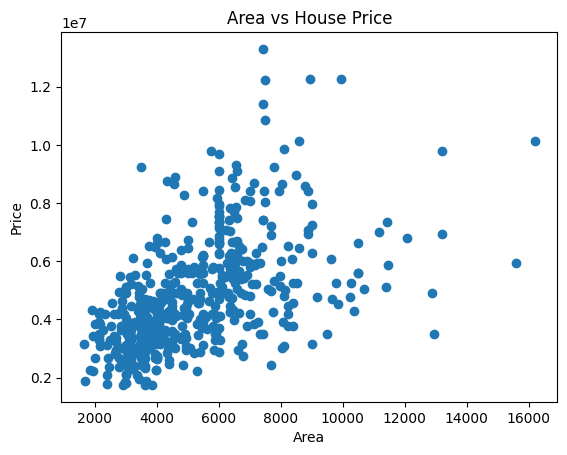

In [18]:
plt.scatter(df['area'], df['price'])

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Area vs House Price")

plt.show()

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 436
Testing Data: 109


In [20]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 2512254.2639593435
Coefficient: 425.72984193878284


In [21]:
print("Regression Equation:")

print(
    f"Price = {model.intercept_:.2f} + "
    f"({model.coef_[0]:.2f} * Area)"
)

Regression Equation:
Price = 2512254.26 + (425.73 * Area)


In [22]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0       4060000     5.024060e+06
1       6650000     5.279498e+06
2       3710000     4.232203e+06
3       6440000     4.640903e+06
4       2800000     4.198144e+06
5       4900000     5.373159e+06
6       5250000     6.139473e+06
7       4543000     4.636646e+06
8       2450000     3.891619e+06
9       3353000     3.661725e+06


In [23]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1474748.1337969352
MSE: 3675286604768.185
RMSE: 1917103.7021424233
R2 Score: 0.27287851871974644


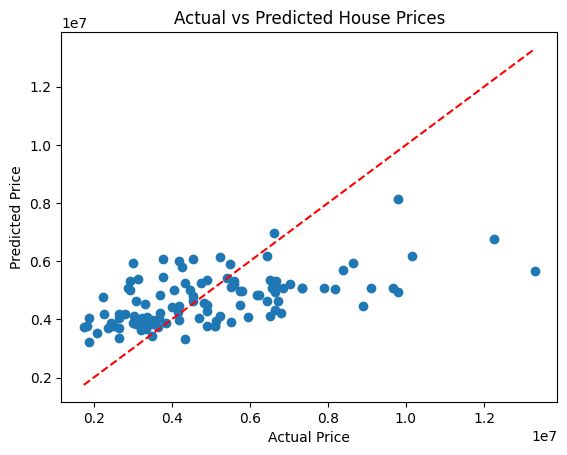

In [24]:
plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [25]:
new_house = pd.DataFrame({
    'area': [5000]
})

prediction = model.predict(new_house)

print("New House Area:", 5000)

print("Predicted House Price:", prediction[0])

New House Area: 5000
Predicted House Price: 4640903.473653258


In [29]:
df.to_csv('cleaned_house_price_data.csv', index=False)

files.download('cleaned_house_price_data.csv')
print("Cleaned House Price Dataset Downloaded Successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned House Price Dataset Downloaded Successfully!
